# Taller 09: Clasificadores Bayesianos
**Inteligencia Artificial – ELP 8012 – Universidad del Norte**
Profesor: Eduardo Zurek, Ph.D.

**Integrantes:**
- Nombre 1
- Nombre 2
- Nombre 3

---

## Objetivo
Diseñar e implementar un clasificador bayesiano que reconozca dígitos escritos a mano del dataset `digits` de scikit-learn, siguiendo estas condiciones:

1. Dividir el dataset en **80 % entrenamiento** y **20 % prueba**.
2. Usar **validación cruzada K-fold con K = 4** durante el entrenamiento.
3. Encontrar el clasificador bayesiano que mejor se adapte a los datos y **justificar qué distribución siguen**.
4. Aplicar **suavizado de Laplace** al clasificador elegido y explicar el **efecto de α** en los indicadores de desempeño.

## Metodología
1. Exploración del dataset y análisis de la distribución de sus características.
2. División estratificada 80/20 (el conjunto de prueba no se toca hasta la evaluación final).
3. Comparación de las cinco variantes de Naive Bayes de scikit-learn (Gaussiano, Multinomial, Bernoulli, Complement y Categórico) con `StratifiedKFold(n_splits=4)` sobre el 80 % de entrenamiento.
4. Barrido del hiperparámetro α (suavizado de Laplace/Lidstone) con K-fold = 4 y selección del mejor valor.
5. Evaluación final sobre el 20 % de prueba.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

from sklearn.datasets import load_digits
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.naive_bayes import (GaussianNB, MultinomialNB, BernoulliNB,
                                 ComplementNB, CategoricalNB)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

## 1. Carga y exploración del dataset

El dataset `digits` contiene 1 797 imágenes de dígitos (0–9) de 8×8 píxeles. Cada imagen se representa como un vector de **64 características**.

Un detalle importante para elegir el clasificador: las imágenes originales eran mapas de bits de 32×32 que se dividieron en bloques de 4×4 sin solapamiento. **Cada característica es el número de píxeles negros dentro de su bloque**, así que solo puede tomar valores **enteros entre 0 y 16**.

In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("Forma de X:", X.shape)
print("Clases:", np.unique(y))
print("Valores distintos en X:", np.unique(X).astype(int))
print("¿Todos los valores son enteros?:", np.all(X == X.astype(int)))
print("Proporción de ceros en X: {:.1%}".format((X == 0).mean()))
print("\nMuestras por clase:")
print(pd.Series(y).value_counts().sort_index().to_frame("n").T)

Forma de X: (1797, 64)
Clases: [0 1 2 3 4 5 6 7 8 9]
Valores distintos en X: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]
¿Todos los valores son enteros?: True
Proporción de ceros en X: 48.9%

Muestras por clase:
     0    1    2    3    4    5    6    7    8    9
n  178  182  177  183  181  182  181  179  174  180


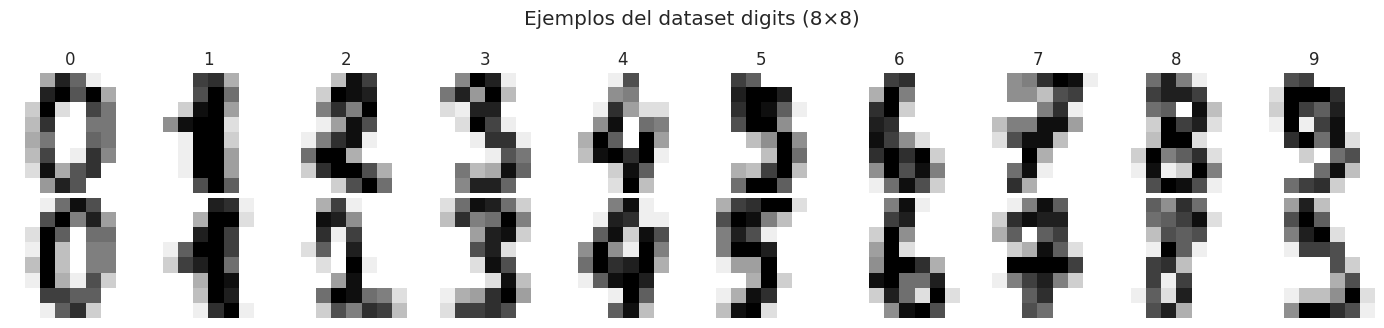

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for d in range(10):
    idx = np.where(y == d)[0][:2]
    for r in range(2):
        axes[r, d].imshow(digits.images[idx[r]], cmap="gray_r")
        axes[r, d].set_title(str(d) if r == 0 else "")
        axes[r, d].axis("off")
plt.suptitle("Ejemplos del dataset digits (8×8)")
plt.tight_layout()
plt.show()

Las clases están prácticamente balanceadas (~180 muestras cada una), por lo que la *accuracy* es un indicador razonable. De todos modos también se reportan *precision*, *recall* y *F1* en promedio macro.

## 2. Análisis de la distribución de los datos

Naive Bayes supone que, dada la clase, cada característica es independiente y sigue una distribución concreta. Cada variante de scikit-learn asume una distribución distinta:

| Clasificador | Distribución asumida para $P(x_i \mid y)$ | Tipo de dato ideal |
|---|---|---|
| `GaussianNB` | Normal $\mathcal{N}(\mu_{iy}, \sigma^2_{iy})$ | Continuo, simétrico, sin acotar |
| `MultinomialNB` | Multinomial (conteos repartidos entre características) | Conteos enteros ≥ 0 |
| `ComplementNB` | Multinomial (estimada sobre el complemento de cada clase) | Conteos con clases desbalanceadas |
| `BernoulliNB` | Bernoulli (binaria) | 0/1 |
| `CategoricalNB` | Categórica (una probabilidad por cada valor posible) | Discreto con pocas categorías |

A continuación se analiza qué forma tienen realmente los datos.

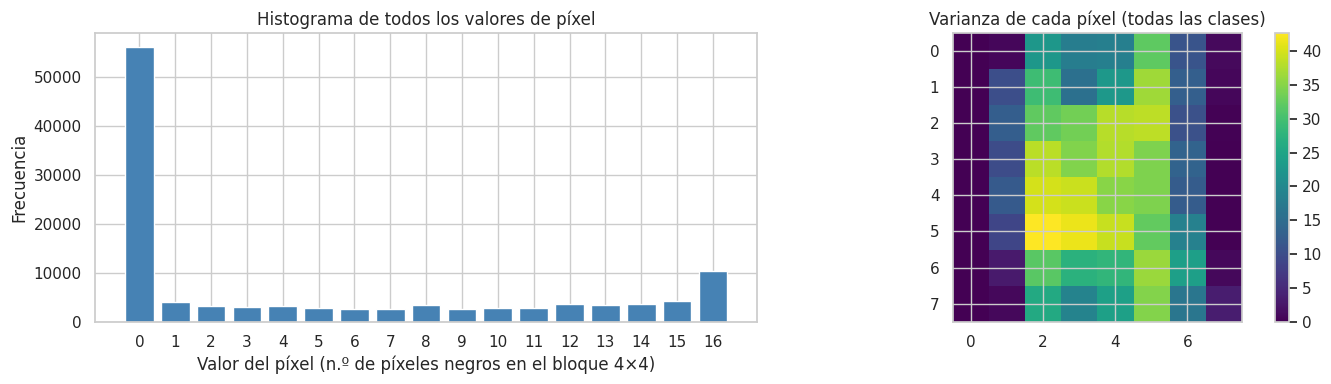

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

vals, counts = np.unique(X, return_counts=True)
axes[0].bar(vals.astype(int), counts, color="steelblue")
axes[0].set_title("Histograma de todos los valores de píxel")
axes[0].set_xlabel("Valor del píxel (n.º de píxeles negros en el bloque 4×4)")
axes[0].set_ylabel("Frecuencia")
axes[0].set_xticks(range(17))

pix_var = X.var(axis=0).reshape(8, 8)
im = axes[1].imshow(pix_var, cmap="viridis")
axes[1].set_title("Varianza de cada píxel (todas las clases)")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

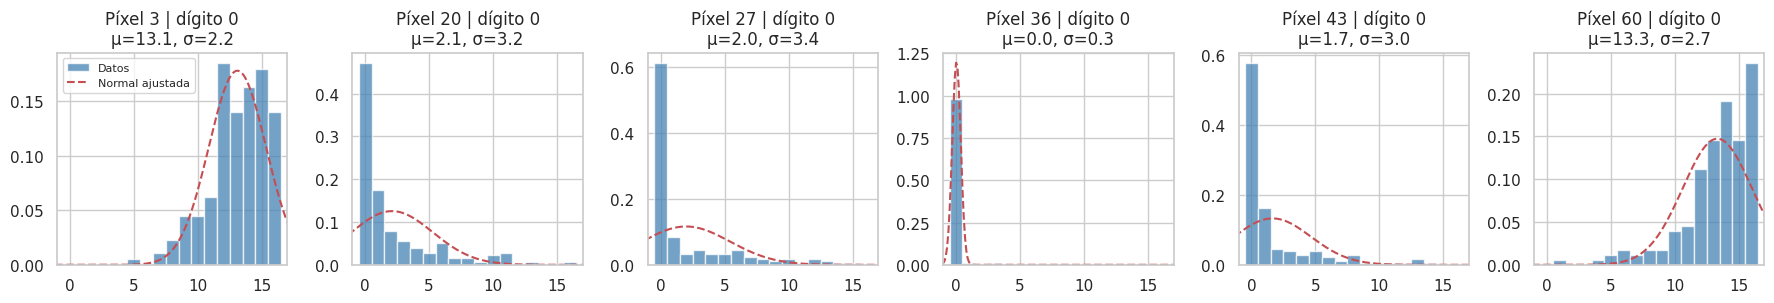

In [5]:
# Distribución de algunos píxeles DENTRO de una misma clase (dígito 0),
# comparada con la normal que asumiría GaussianNB
clase = 0
pixeles = [3, 20, 27, 36, 43, 60]
Xc = X[y == clase]

fig, axes = plt.subplots(1, len(pixeles), figsize=(18, 3.2))
for ax, p in zip(axes, pixeles):
    v = Xc[:, p]
    ax.hist(v, bins=np.arange(-0.5, 17.5, 1), density=True,
            color="steelblue", alpha=0.75, label="Datos")
    if v.std() > 0:
        xs = np.linspace(-2, 18, 200)
        ax.plot(xs, stats.norm.pdf(xs, v.mean(), v.std()), "r--", label="Normal ajustada")
    ax.set_title(f"Píxel {p} | dígito {clase}\nμ={v.mean():.1f}, σ={v.std():.1f}")
    ax.set_xlim(-1, 17)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
# Prueba de normalidad (D'Agostino-Pearson) para cada par (clase, píxel)
pvals, var_cero = [], 0
for c in range(10):
    for j in range(64):
        v = X[y == c, j]
        if v.std() == 0:
            var_cero += 1
        else:
            pvals.append(stats.normaltest(v).pvalue)
pvals = np.array(pvals)

print(f"Pares (clase, píxel) evaluados: {len(pvals)}")
print(f"Pares donde se rechaza normalidad (p < 0.05): {(pvals < 0.05).mean():.1%}")
print(f"Pares con varianza CERO (siempre el mismo valor): {var_cero} de 640")

asim = pd.DataFrame(X).skew()
print(f"\nAsimetría (skewness) media de los píxeles: {asim.mean():.2f}")
print(f"Píxeles con |asimetría| > 1: {(asim.abs() > 1).sum()} de 64")

Pares (clase, píxel) evaluados: 517
Pares donde se rechaza normalidad (p < 0.05): 98.5%
Pares con varianza CERO (siempre el mismo valor): 123 de 640

Asimetría (skewness) media de los píxeles: 4.31
Píxeles con |asimetría| > 1: 32 de 64


### Conclusiones sobre la distribución

- **Los datos son discretos y acotados:** cada característica es un conteo entero en $\{0, 1, \dots, 16\}$, es decir, solo 17 valores posibles.
- **No son normales:** en el 98,5 % de los pares (clase, píxel) la prueba de D'Agostino-Pearson rechaza la normalidad. Las distribuciones están muy sesgadas y se acumulan contra los extremos (0 o 16). La normal ajustada asigna probabilidad a valores imposibles (negativos o mayores que 16) y no captura la gran masa en 0.
- **Hay 123 pares (clase, píxel) con varianza cero** (por ejemplo, los bordes de la imagen siempre valen 0). Ahí la gaussiana no está definida y `GaussianNB` depende de `var_smoothing` para no dividir por cero.
- **Casi la mitad de los valores son 0**, típico de imágenes con fondo blanco.

Por esto se esperan mejores resultados de los modelos **discretos**:
- `CategoricalNB` modela cada píxel como una **variable categórica con 17 valores** y aprende, para cada clase, una probabilidad específica para cada valor. Así captura la forma real (sesgada o bimodal) de cada histograma.
- `MultinomialNB` interpreta la imagen como **conteos de "tinta"** repartidos entre los 64 píxeles, lo que también es coherente con el origen de los datos.
- `BernoulliNB` solo ve si el píxel está "encendido" o "apagado" y pierde la información de intensidad.

La comparación con K-fold confirma o descarta esta hipótesis.

## 3. División 80 % entrenamiento / 20 % prueba

La división es **estratificada** para conservar la proporción de cada dígito en ambos subconjuntos. El 20 % de prueba se reserva y solo se usa al final.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Entrenamiento:", X_train.shape, f"({len(X_train)/len(X):.0%})")
print("Prueba:       ", X_test.shape,  f"({len(X_test)/len(X):.0%})")

Entrenamiento: (1437, 64) (80%)
Prueba:        (360, 64) (20%)


## 4. Comparación de clasificadores bayesianos con K-fold = 4

Se usa `StratifiedKFold(n_splits=4)` sobre el conjunto de entrenamiento: en cada iteración se entrena con 3/4 de los datos y se valida con el 1/4 restante. Se reportan la media y la desviación estándar de cada métrica.

Notas de configuración:
- `BernoulliNB(binarize=8)`: el píxel se considera "encendido" si tiene al menos la mitad de su bloque en negro.
- `CategoricalNB(min_categories=17)`: garantiza que el modelo conozca las 17 categorías posibles (0–16), aunque algún valor no aparezca en un fold de entrenamiento.
- Todos los modelos usan sus parámetros por defecto (α = 1 en los discretos), para compararlos en igualdad de condiciones.

In [8]:
kfold = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

modelos = {
    "GaussianNB":    GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "BernoulliNB":   BernoulliNB(binarize=8),
    "ComplementNB":  ComplementNB(),
    "CategoricalNB": CategoricalNB(min_categories=17),
}

filas, acc_folds = [], {}
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=kfold, scoring=scoring)
    acc_folds[nombre] = r["test_accuracy"]
    fila = {"Modelo": nombre}
    for m in scoring:
        fila[m] = r[f"test_{m}"].mean()
    fila["accuracy_std"] = r["test_accuracy"].std()
    filas.append(fila)

resultados = pd.DataFrame(filas).set_index("Modelo").sort_values("accuracy", ascending=False)
resultados.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce")

,accuracy,precision_macro,recall_macro,f1_macro,accuracy_std
Modelo,,,,,
CategoricalNB,0.9068,0.9091,0.9064,0.9061,0.0170
MultinomialNB,0.9047,0.9121,0.9048,0.9050,0.0114
BernoulliNB,0.8845,0.8904,0.8845,0.8851,0.0126
GaussianNB,0.8232,0.8652,0.8233,0.8240,0.0050
ComplementNB,0.8170,0.8411,0.8153,0.8007,0.0101


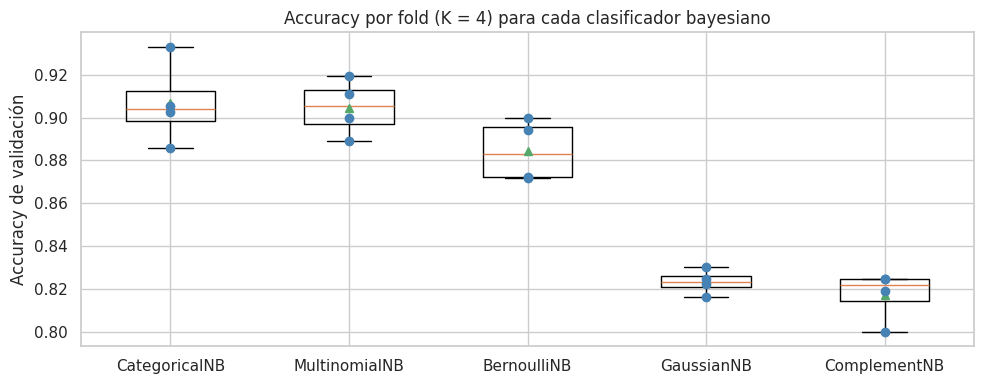

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
orden = resultados.index.tolist()
ax.boxplot([acc_folds[n] for n in orden], labels=orden, showmeans=True)
for i, n in enumerate(orden, start=1):
    ax.scatter(np.full(4, i), acc_folds[n], color="steelblue", zorder=3)
ax.set_ylabel("Accuracy de validación")
ax.set_title("Accuracy por fold (K = 4) para cada clasificador bayesiano")
plt.tight_layout()
plt.show()

### Elección del clasificador

Los resultados confirman el análisis de la sección 2 (la variabilidad entre folds es de ≈ 1–2 puntos):

1. **`CategoricalNB` y `MultinomialNB` obtienen los mejores resultados** (≈ 90–91 % de accuracy y F1 macro). Ambos son modelos para **datos discretos**, que es justamente el tipo de dato que tenemos.
2. `BernoulliNB` queda un poco atrás porque, al binarizar, descarta la intensidad del píxel.
3. **`GaussianNB` rinde bastante peor**, ya que la suposición de normalidad es falsa: los histogramas son sesgados, acotados y bimodales, y hay características con varianza cero.
4. `ComplementNB` está pensado para clases desbalanceadas (sobre todo en texto). Aquí las clases están balanceadas, así que no aporta ventaja y su F1 baja.

**Clasificador elegido: `CategoricalNB`.**
Justificación: cada característica es una variable discreta con solo 17 valores posibles (0–16). La distribución categórica no impone ninguna forma a priori y estima directamente $P(x_i = t \mid y = c)$ para cada valor $t$. Eso le permite reproducir la forma real de cada píxel en cada dígito (sesgada o acumulada en 0 o en 16), algo que la normal no puede hacer. Es el modelo con mejor desempeño medio en la validación cruzada.

> `MultinomialNB` queda prácticamente empatado y es una alternativa válida. Más adelante se muestra que, con este dataset, casi no reacciona a α, mientras que `CategoricalNB` sí depende mucho del suavizado. Esto convierte a `CategoricalNB` en el caso más interesante para estudiar el suavizado de Laplace.

## 5. Suavizado de Laplace

### ¿Qué es y por qué hace falta?

`CategoricalNB` estima cada probabilidad por **frecuencia relativa**. Con suavizado aditivo (Laplace/Lidstone) la estimación es:

$$
P(x_i = t \mid y = c) = \frac{N_{tic} + \alpha}{N_c + \alpha \, n_i}
$$

donde $N_{tic}$ es el número de muestras de la clase $c$ en las que el píxel $i$ vale $t$, $N_c$ es el número de muestras de la clase $c$ y $n_i = 17$ es el número de categorías posibles.

- Con **α = 0** (sin suavizado), si un valor nunca se observó en entrenamiento para una clase, su probabilidad es **exactamente 0**. Como Naive Bayes **multiplica** las probabilidades de los 64 píxeles, un solo cero anula toda la clase, aunque los otros 63 píxeles coincidan perfectamente. Este es el **problema de la frecuencia cero**.
- **α = 1** es el suavizado de Laplace clásico: se suma una "observación ficticia" a cada categoría.
- **0 < α < 1** se conoce como suavizado de Lidstone.

Veamos qué tan frecuente es el problema en nuestros datos:

In [10]:
conteos = np.zeros((10, 64, 17), dtype=int)
for c in range(10):
    for j in range(64):
        conteos[c, j] = np.bincount(X_train[y_train == c, j].astype(int), minlength=17)

print(f"Combinaciones (clase, píxel, valor) posibles: {conteos.size}")
print(f"Combinaciones NUNCA observadas en entrenamiento: {(conteos == 0).sum()} "
      f"({(conteos == 0).mean():.1%})")

# Cuántas muestras de prueba tienen al menos un píxel con valor nunca visto para SU clase real
no_vistos = np.array([
    np.sum(conteos[yt, np.arange(64), xt.astype(int)] == 0)
    for xt, yt in zip(X_test, y_test)
])
print(f"\nMuestras de prueba con ≥1 píxel cuyo valor nunca se vio en su clase real: "
      f"{(no_vistos > 0).mean():.1%}")
print("→ Sin suavizado, a esas muestras se les asignaría probabilidad 0 para su clase correcta.")

Combinaciones (clase, píxel, valor) posibles: 10880
Combinaciones NUNCA observadas en entrenamiento: 4227 (38.9%)

Muestras de prueba con ≥1 píxel cuyo valor nunca se vio en su clase real: 36.7%
→ Sin suavizado, a esas muestras se les asignaría probabilidad 0 para su clase correcta.


### Barrido de α con K-fold = 4

Se evalúa `CategoricalNB` con una amplia gama de valores de α (escala logarítmica, desde $10^{-10}$, que equivale en la práctica a "sin suavizado", hasta 1000). Para cada α se calculan, con K-fold = 4, la *accuracy*, *precision*, *recall* y *F1* macro en validación, y también la *accuracy* en entrenamiento para observar el sobreajuste.

In [11]:
alphas = [1e-10, 1e-6, 1e-4, 1e-3, 0.01, 0.05, 0.1, 0.25, 0.5, 0.75,
          1, 1.5, 2, 5, 10, 20, 50, 100, 1000]

def barrido_alpha(make_model):
    filas = []
    for a in alphas:
        r = cross_validate(make_model(a), X_train, y_train, cv=kfold,
                           scoring=scoring, return_train_score=True)
        fila = {"alpha": a, "train_accuracy": r["train_accuracy"].mean()}
        for m in scoring:
            fila[m] = r[f"test_{m}"].mean()
        fila["accuracy_std"] = r["test_accuracy"].std()
        filas.append(fila)
    return pd.DataFrame(filas)

df_cat = barrido_alpha(lambda a: CategoricalNB(alpha=a, min_categories=17))
df_cat.style.format({"alpha": "{:g}"} | {c: "{:.4f}" for c in df_cat.columns if c != "alpha"}) \
      .highlight_max(subset=scoring, color="#c6efce")

,alpha,train_accuracy,accuracy,precision_macro,recall_macro,f1_macro,accuracy_std
0,1e-10,0.9926,0.8441,0.8609,0.8443,0.8458,0.0064
1,1e-06,0.9903,0.8657,0.8784,0.8659,0.8670,0.0108
2,0.0001,0.9896,0.8810,0.8898,0.8811,0.8816,0.0132
3,0.001,0.9877,0.8928,0.8998,0.8928,0.8932,0.0112
4,0.01,0.9849,0.8970,0.9025,0.8970,0.8972,0.0131
5,0.05,0.9812,0.9033,0.9073,0.9031,0.9034,0.0133
6,0.1,0.9789,0.9061,0.9096,0.9059,0.9061,0.0117
7,0.25,0.9773,0.9109,0.9137,0.9108,0.9108,0.0132
8,0.5,0.9731,0.9088,0.9108,0.9086,0.9085,0.0169
9,0.75,0.9708,0.9088,0.9110,0.9085,0.9084,0.0178


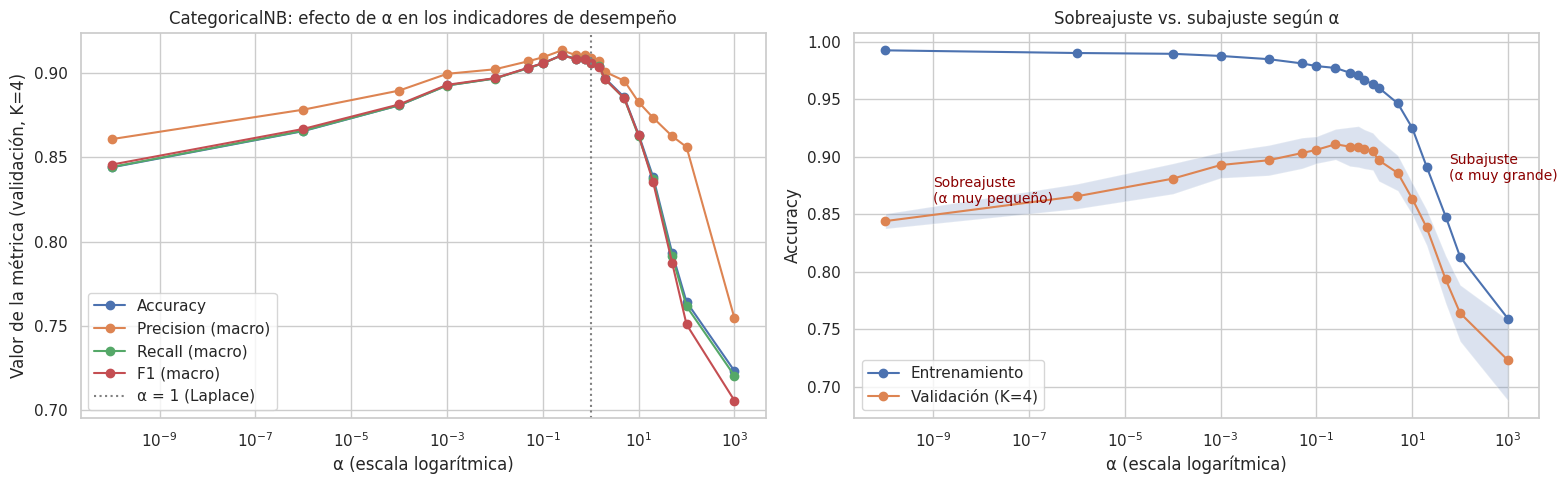

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
etiquetas = {"accuracy": "Accuracy", "precision_macro": "Precision (macro)",
             "recall_macro": "Recall (macro)", "f1_macro": "F1 (macro)"}
for m, lab in etiquetas.items():
    ax.plot(df_cat["alpha"], df_cat[m], marker="o", label=lab)
ax.axvline(1, color="gray", ls=":", label="α = 1 (Laplace)")
ax.set_xscale("log")
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Valor de la métrica (validación, K=4)")
ax.set_title("CategoricalNB: efecto de α en los indicadores de desempeño")
ax.legend()

ax = axes[1]
ax.plot(df_cat["alpha"], df_cat["train_accuracy"], marker="o", label="Entrenamiento")
ax.plot(df_cat["alpha"], df_cat["accuracy"], marker="o", label="Validación (K=4)")
ax.fill_between(df_cat["alpha"], df_cat["accuracy"] - df_cat["accuracy_std"],
                df_cat["accuracy"] + df_cat["accuracy_std"], alpha=0.2)
ax.set_xscale("log")
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Accuracy")
ax.set_title("Sobreajuste vs. subajuste según α")
ax.annotate("Sobreajuste\n(α muy pequeño)", xy=(1e-9, 0.86), fontsize=10, color="darkred")
ax.annotate("Subajuste\n(α muy grande)", xy=(60, 0.88), fontsize=10, color="darkred")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Comparación: efecto de α en `MultinomialNB`

Como referencia, se repite el mismo barrido con `MultinomialNB`.

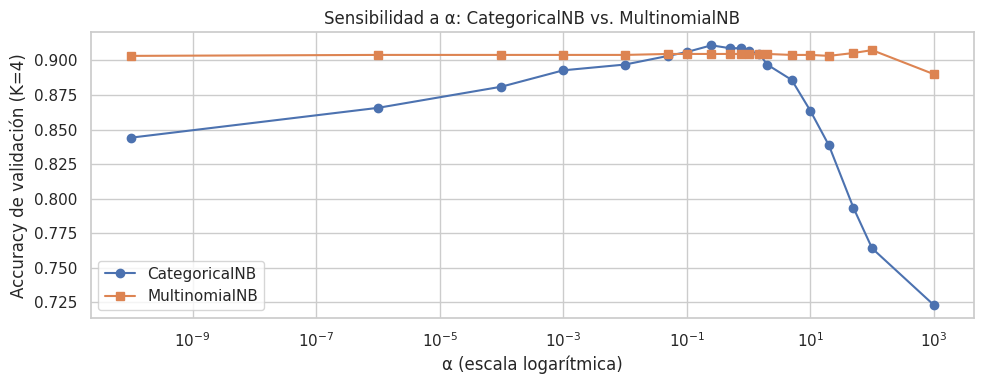

Rango de accuracy al variar α → CategoricalNB: 0.723 – 0.911
Rango de accuracy al variar α → MultinomialNB: 0.890 – 0.907


In [13]:
df_mult = barrido_alpha(lambda a: MultinomialNB(alpha=a))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df_cat["alpha"], df_cat["accuracy"], marker="o", label="CategoricalNB")
ax.plot(df_mult["alpha"], df_mult["accuracy"], marker="s", label="MultinomialNB")
ax.set_xscale("log")
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Accuracy de validación (K=4)")
ax.set_title("Sensibilidad a α: CategoricalNB vs. MultinomialNB")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Rango de accuracy al variar α → CategoricalNB: "
      f"{df_cat['accuracy'].min():.3f} – {df_cat['accuracy'].max():.3f}")
print(f"Rango de accuracy al variar α → MultinomialNB: "
      f"{df_mult['accuracy'].min():.3f} – {df_mult['accuracy'].max():.3f}")

`MultinomialNB` es casi insensible a α porque estima **una sola probabilidad por píxel y clase** a partir de la suma de toda la "tinta" de la clase, que son miles de unidades. Sumarle un α pequeño a esos totales casi no cambia nada, y además casi ningún conteo es cero. Solo con α muy grande (≈1000) empieza a notarse el efecto.

`CategoricalNB`, en cambio, reparte las ~144 muestras de cada clase entre **17 categorías por píxel**, así que muchos conteos son 0 o muy pequeños. Por eso α tiene un efecto fuerte.

### Selección del mejor α con `GridSearchCV` (K = 4)

Mejor α: 0.2
Accuracy media de validación (K=4): 0.9109


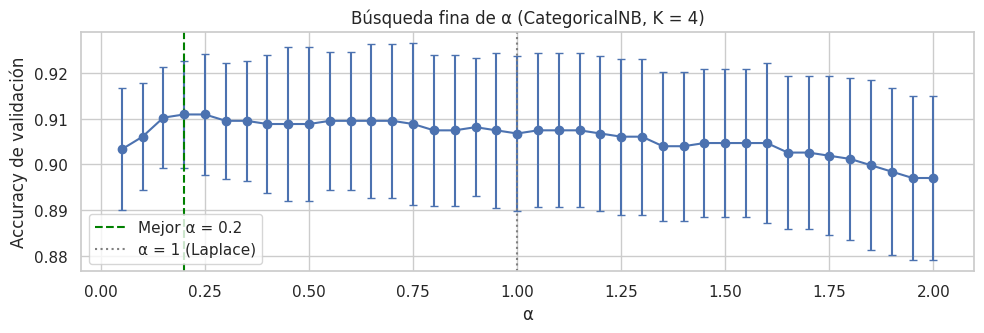

In [14]:
grid = GridSearchCV(
    CategoricalNB(min_categories=17),
    param_grid={"alpha": np.round(np.arange(0.05, 2.01, 0.05), 2)},
    cv=kfold, scoring="accuracy", refit=True)
grid.fit(X_train, y_train)

mejor_alpha = grid.best_params_["alpha"]
print(f"Mejor α: {mejor_alpha}")
print(f"Accuracy media de validación (K=4): {grid.best_score_:.4f}")

cvres = pd.DataFrame(grid.cv_results_)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(cvres["param_alpha"].astype(float), cvres["mean_test_score"],
            yerr=cvres["std_test_score"], marker="o", capsize=3)
ax.axvline(mejor_alpha, color="green", ls="--", label=f"Mejor α = {mejor_alpha}")
ax.axvline(1, color="gray", ls=":", label="α = 1 (Laplace)")
ax.set_xlabel("α")
ax.set_ylabel("Accuracy de validación")
ax.set_title("Búsqueda fina de α (CategoricalNB, K = 4)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluación final en el conjunto de prueba (20 %)

Se entrena el modelo con todo el 80 % de entrenamiento usando el mejor α y se evalúa **una sola vez** sobre el 20 % reservado.

In [15]:
modelo_final = grid.best_estimator_
y_pred = modelo_final.predict(X_test)

print(f"CategoricalNB (α = {mejor_alpha}) – Resultados en PRUEBA")
print(f"  Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"  Precision (macro): {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"  Recall (macro):    {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"  F1 (macro):        {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, digits=4))

CategoricalNB (α = 0.2) – Resultados en PRUEBA
  Accuracy:          0.9083
  Precision (macro): 0.9094
  Recall (macro):    0.9081
  F1 (macro):        0.9081

              precision    recall  f1-score   support

           0     1.0000    0.9444    0.9714        36
           1     0.8056    0.8056    0.8056        36
           2     0.9167    0.9429    0.9296        35
           3     1.0000    1.0000    1.0000        37
           4     0.8947    0.9444    0.9189        36
           5     0.9412    0.8649    0.9014        37
           6     0.9714    0.9444    0.9577        36
           7     0.8750    0.9722    0.9211        36
           8     0.8788    0.8286    0.8529        35
           9     0.8108    0.8333    0.8219        36

    accuracy                         0.9083       360
   macro avg     0.9094    0.9081    0.9081       360
weighted avg     0.9098    0.9083    0.9084       360



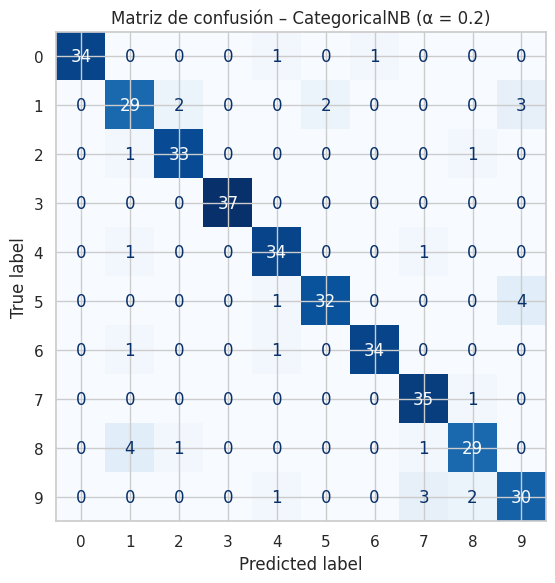

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Matriz de confusión – CategoricalNB (α = {mejor_alpha})")
plt.tight_layout()
plt.show()

In [17]:
# Efecto de α también en el conjunto de prueba
filas = []
for a in [1e-10, 0.01, 0.1, mejor_alpha, 1, 10, 100, 1000]:
    m = CategoricalNB(alpha=a, min_categories=17).fit(X_train, y_train)
    yp = m.predict(X_test)
    filas.append({"alpha": a,
                  "train_accuracy": m.score(X_train, y_train),
                  "test_accuracy": accuracy_score(y_test, yp),
                  "test_precision": precision_score(y_test, yp, average="macro"),
                  "test_recall": recall_score(y_test, yp, average="macro"),
                  "test_f1": f1_score(y_test, yp, average="macro")})
df_test = pd.DataFrame(filas).drop_duplicates("alpha").sort_values("alpha")
df_test.style.format({"alpha": "{:g}"} | {c: "{:.4f}" for c in df_test.columns if c != "alpha"}) \
       .highlight_max(subset=["test_accuracy", "test_f1"], color="#c6efce")

,alpha,train_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,1e-10,0.9868,0.8861,0.8918,0.8866,0.8847
1,0.01,0.9791,0.9139,0.9158,0.9139,0.9132
2,0.1,0.9743,0.9111,0.9121,0.9109,0.9103
3,0.2,0.9715,0.9083,0.9094,0.9081,0.9081
4,1,0.9596,0.8972,0.8974,0.8968,0.8965
5,10,0.9241,0.8583,0.8661,0.8570,0.8524
6,100,0.8142,0.7722,0.8600,0.7694,0.7482
7,1000,0.7599,0.7444,0.7604,0.7413,0.7220


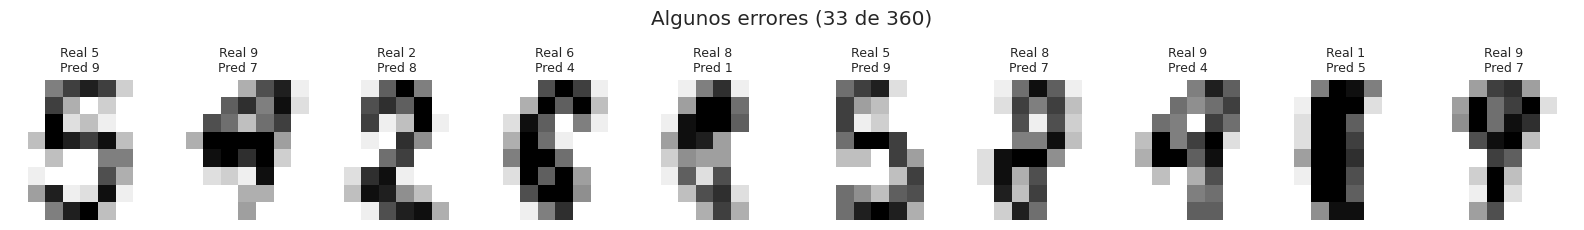

In [18]:
# Ejemplos de dígitos mal clasificados
errores = np.where(y_pred != y_test)[0]
n = min(10, len(errores))
fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
for ax, i in zip(np.atleast_1d(axes), errores[:n]):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Real {y_test[i]}\nPred {y_pred[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Algunos errores ({len(errores)} de {len(y_test)})", y=1.05)
plt.tight_layout()
plt.show()

## 7. Efecto de α en los indicadores de desempeño

Las gráficas y tablas anteriores muestran un comportamiento en forma de **"U invertida"**, consecuencia del compromiso entre **sesgo y varianza**:

**α muy pequeño (≈ 0, sin suavizado) → sobreajuste (alta varianza)**
- La *accuracy* de entrenamiento es la más alta (≈ 99 %), pero la de validación y la de prueba bajan varios puntos. Hay una brecha grande entre entrenamiento y validación.
- Causa: ~39 % de las combinaciones (clase, píxel, valor) no aparecen en entrenamiento, así que su probabilidad es ≈ 0. Cuando una imagen nueva tiene, en un solo píxel, un valor "nunca visto" para su clase real, esa clase recibe una probabilidad casi nula aunque el resto de la imagen coincida. El modelo memoriza los valores exactos vistos y generaliza mal.
- *Accuracy*, *precision*, *recall* y *F1* bajan juntas porque los errores se reparten entre todas las clases.

**α intermedio (≈ 0,5 – 1) → mejor desempeño**
- Se asigna una probabilidad pequeña pero no nula a los valores no observados. El modelo deja de "vetar" una clase por un solo píxel atípico y se reduce la brecha entre entrenamiento y validación.
- Aquí se alcanzan los máximos de las cuatro métricas. El óptimo encontrado con K = 4 (α ≈ 0,2–0,25) es un suavizado de Lidstone más suave que el de Laplace clásico (α = 1), aunque la diferencia entre ambos es de menos de un punto.
- En prueba, un α todavía menor (0,01) acierta 2 imágenes más que α = 0,2. Esa diferencia está dentro del ruido (cada imagen vale 0,28 %). El α se elige con la validación cruzada y no mirando el conjunto de prueba, para no contaminar la evaluación final.

**α grande (≥ 5–10) → subajuste (alto sesgo)**
- Las pseudo-cuentas α empiezan a pesar más que los datos reales. Cada clase tiene ~144 muestras de entrenamiento y hay 17 categorías: con α = 100 se suman 1 700 cuentas ficticias por píxel, más de diez veces los datos reales.
- Las distribuciones $P(x_i \mid y)$ se aplanan hacia la **uniforme** (1/17 para cada valor), las clases se parecen cada vez más entre sí y el modelo pierde capacidad de discriminar. Todas las métricas caen, tanto en entrenamiento como en validación.
- Las métricas no caen al mismo ritmo: con α = 100 la *precision* macro sigue en ≈ 0,86 mientras el *recall* y el *F1* bajan a ≈ 0,76 y ≈ 0,75. Con tanto suavizado el modelo empieza a favorecer algunas clases y a dejar de predecir otras: las clases favorecidas pierden poca precisión, pero las olvidadas pierden mucho recall. Por eso el F1 es el indicador que más se degrada.

**Resumen:** α regula cuánto confiamos en las frecuencias observadas frente a una distribución uniforme a priori. Desde un punto de vista bayesiano, equivale a usar un **prior de Dirichlet** simétrico con parámetro α sobre las probabilidades de cada categoría. Muy poco suavizado lleva a sobreajuste, demasiado suavizado lleva a subajuste, y el valor óptimo se elige con validación cruzada.

## 8. Conclusiones

1. Las características del dataset `digits` son **conteos enteros discretos en el rango 0–16**, con distribuciones sesgadas, acumuladas en los extremos y con muchos ceros. **No siguen una distribución normal.**
2. Por eso los clasificadores bayesianos discretos superan claramente a `GaussianNB`. El mejor en validación cruzada K-fold = 4 fue **`CategoricalNB`**, que modela cada píxel como una variable categórica de 17 valores. `MultinomialNB` quedó muy cerca.
3. El **suavizado de Laplace es indispensable** en `CategoricalNB`: sin él, cerca del 39 % de las probabilidades estimadas son cero y el modelo sobreajusta.
4. α controla el compromiso sesgo-varianza. El valor óptimo encontrado con K = 4 está alrededor de **α ≈ 0,2**, y valores muy grandes degradan todos los indicadores por exceso de suavizado.
5. El modelo final (α = 0,2) logra **≈ 90,8 % de accuracy y F1 macro en el conjunto de prueba**, un resultado sólido para un clasificador tan simple que asume independencia entre píxeles (supuesto que no se cumple del todo, porque los píxeles vecinos están correlacionados).